# Demonstration of 3D fully vectorial simulations benchmarking [Numba, CUDA, CuPy] GPU-accelerated frameworks

This notebook demonstrates the generation and analysis of a three-dimensional heat source.

- implicit and direct linear algebra solvers
- CUDA on / off nested for  loops


## 1. Import libraries and generate heat sources
- Refer to NoteBook 1 for a refresher on importing modules.
- In this notebook we will see how the 3D methods inherit from their 2D ancestors.


<div class="alert alert-block alert-info"> **Info:** Here we create an instance of the 3D `varoptic.heateqn.HeatEqn3D` object and use the `get_explicit_fd_params` method [overridden](https://docs.python.org/2/tutorial/classes.html "Python Classes Turorial") from the parent class `HeatEqn2D`.</div>

In [3]:
import os, sys
module_path = os.path.abspath(os.path.join('../src/'))
if module_path not in sys.path:
    sys.path.append(module_path)
import importlib
import varoptic
import numpy as np

importlib.reload(varoptic.heateqn)
#mygauss3dQ = varoptic.heateqn.HeatEqn3D(50,40,30,35,0.4,0.8) # Testing meshgrid indices
#mygauss3dQ.add_gaussian_source(b_y=100)                      # b_x = 250 Compensate for rectanglular crystal face
mygauss3dQ = varoptic.heateqn.HeatEqn3D(100,100,50,30)
mygauss3dQ.add_gaussian_source()
mygauss3dQ.plot_source_profile(savepath='images/nb4_sourceq.png')
mygauss3dQ.plot_source_profile(savepath='images/nb4_sourceq_z_01cm.png', z=0.1)
[[xx, yy, clock, Tinit, Qload, sx, sy], zz, sz, alpha, dz] = mygauss3dQ.get_explicit_fd_params()

<img width="640" height="480" src="images/nb3_sourceq.png">

<img width="640" height="480" src="images/nb3_sourceq_z_01cm.png">

<div class="alert alert-block alert-success"> **Tip:** Many of the modules are built with exception handling. Should you try to visualize the cross-sectional heat profile of the crystal / lens beyond the extent of it's physical axial length, a `ValueError` exception will be raised. And remember to press `F5` to refresh the page if the image is not updating.</div>

## 2. Solve and Visualize 3D heat equation using finite differences

- Create `FDSolver3D` object using the integration parameters retrieved from the `mygauss3dQ` object.
- Specify unique paths for thermal and source profiles in databse.

<div class="alert alert-block alert-danger"> **Warning:** If you've generated other profiles in corresponding notebooks for later analysis, ensure that you use different paths fo the thermal and phase profiles in the in the hierarchical data format `storage.hdf5` file.</div>

In [4]:
importlib.reload(varoptic.fdsolver)
myfd = varoptic.fdsolver.FDSolver3D(clock.size, np.shape(zz)[2], Tinit, Qload, sx, sy, sz, zz, alpha, dz,
                                    hdf5grp='nb4', hdf5filename='hdf5db/storage.hdf5', hdf5table='temperature',
                                    hdf5tabledrive='qinit')
myfdcalc = myfd.explicit_method()

(100, 100, 50)
[ 293.18529052  293.18387909  293.18252411  293.18122333  293.17997456
  293.17877574  293.17762487  293.17652003  293.17545937  293.17444113
  293.17346362  293.1725252   293.17162432  293.17075946  293.1699292
  293.16913214  293.16836696  293.16763238  293.16692718  293.16625018
  293.16560027  293.16497634  293.16437737  293.16380235  293.16325033
  293.16272039  293.16221164  293.16172325  293.16125438  293.16080427
  293.16037215  293.15995732  293.15955909  293.15917677  293.15880975
  293.15845741  293.15811916  293.15779444  293.1574827   293.15718344
  293.15689614  293.15662033  293.15635555  293.15610136  293.15585734
  293.15562308  293.15539819  293.15518229  293.15497503  293.15477605]
hf:  [ 293.15  293.15  293.15  293.15  293.15  293.15  293.15  293.15  293.15
  293.15  293.15  293.15  293.15  293.15  293.15  293.15  293.15  293.15
  293.15  293.15  293.15  293.15  293.15  293.15  293.15  293.15  293.15
  293.15  293.15  293.15  293.15  293.15  293.15  2

[ 293.38987502  293.38237413  293.37339505  293.36449218  293.3559157
  293.34768027  293.33977414  293.3321842   293.32489783  293.31790287
  293.31118766  293.30474104  293.29855224  293.29261095  293.28690729
  293.28143175  293.27617519  293.27112887  293.26628437  293.26163363
  293.25716889  293.25288272  293.24876797  293.24481779  293.2410256
  293.23738507  293.23389014  293.23053499  293.22731403  293.22422189
  293.22125342  293.21840367  293.21566789  293.21304153  293.21052022
  293.20809974  293.20577606  293.20354532  293.2014038   293.19934793
  293.19737428  293.19547957  293.19366063  293.19191445  293.1902381
  293.1886288   293.18708414  293.18560529  293.18422423  293.18314254]
hf:  [ 293.35656075  293.349884    293.34208762  293.33442053  293.32704538
  293.31996454  293.31316689  293.3066411   293.30037631  293.29436207
  293.28858838  293.2830456   293.2777245   293.27261621  293.26771223
  293.26300438  293.25848482  293.25414602  293.24998074  293.24598206
  2

[ 293.58394717  293.5723733   293.55703767  293.54109399  293.52550991
  293.51049937  293.49608219  293.48224085  293.46895303  293.45619664
  293.44395044  293.43219402  293.4209078   293.41007296  293.39967146
  293.38968596  293.38009982  293.37089708  293.3620624   293.35358106
  293.34543892  293.33762243  293.33011855  293.32291479  293.31599914
  293.30936008  293.30298654  293.29686791  293.290994    293.285355
  293.27994154  293.27474459  293.26975548  293.26496591  293.2603679
  293.25595379  293.25171621  293.24764812  293.24374272  293.23999352
  293.23639427  293.23293897  293.22962187  293.22643743  293.22338047
  293.22044671  293.21763711  293.21497815  293.21259458  293.21089546]
hf:  [ 293.55225983  293.54128402  293.52692691  293.51210895  293.49766653
  293.48376659  293.47041818  293.45760323  293.44530078  293.43349035
  293.42215228  293.41126767  293.40081839  293.39078702  293.38115685
  293.37191183  293.36303656  293.35451626  293.34633672  293.33848432
  2

[ 293.76899824  293.75429075  293.73363874  293.71134795  293.68916452
  293.66765856  293.64696556  293.62709127  293.60801042  293.58969252
  293.57210722  293.55522522  293.53901842  293.5234598   293.50852344
  293.49418445  293.48041895  293.46720399  293.45451756  293.44233851
  293.43064656  293.41942223  293.4086468   293.39830234  293.38837159
  293.37883803  293.36968575  293.36089952  293.35246468  293.3443672
  293.33659356  293.32913084  293.32196658  293.31508885  293.3084862
  293.30214761  293.29606254  293.29022083  293.28461276  293.27922898
  293.27406053  293.26909878  293.26433551  293.25976293  293.25537446
  293.251168    293.2471588   293.24341907  293.24017424  293.23798281]
hf:  [ 293.7387374   293.72450659  293.7046812   293.68340092  293.66228646
  293.64184229  293.62217887  293.60329537  293.58516615  293.56776189
  293.55105369  293.53501372  293.51961527  293.50483267  293.49064129
  293.47701749  293.46393857  293.45138274  293.43932907  293.42775748
  

[ 293.94601467  293.92873356  293.90353164  293.87554454  293.84721328
  293.81952126  293.79279121  293.76709376  293.74241493  293.71872196
  293.69597648  293.67413997  293.65317748  293.6330531   293.61373363
  293.59518678  293.57738174  293.56028858  293.54387978  293.52812628
  293.5130032   293.49848581  293.48454719  293.47116808  293.4583224
  293.44599182  293.43415305  293.4227892   293.41187837  293.40140545
  293.39134978  293.38169781  293.37243084  293.36353459  293.35499501
  293.34679553  293.33892534  293.33136936  293.32411504  293.31715207
  293.31046681  293.30404823  293.29788853  293.29197433  293.28630327
  293.28087822  293.27573982  293.27101235  293.26701144  293.26440345]
hf:  [ 293.91703573  293.90015391  293.87566541  293.84858661  293.82124819
  293.79456467  293.76882423  293.74408238  293.72032393  293.69751425
  293.67561659  293.65459497  293.63441381  293.6150399   293.59644082
  293.57858563  293.56144454  293.54498908  293.52919145  293.51402605
 

[[[ 293.15        293.15        293.15       ...,  293.15        293.15
    293.15      ]
  [ 293.15        293.15        293.15       ...,  293.15        293.15
    293.15      ]
  [ 293.15        293.15        293.15       ...,  293.15        293.15
    293.15      ]
  ..., 
  [ 293.15        293.15        293.15       ...,  293.15        293.15
    293.15      ]
  [ 293.15        293.15        293.15       ...,  293.15        293.15
    293.15      ]
  [ 293.15        293.15        293.15       ...,  293.15        293.15
    293.15      ]]

 [[ 293.15        293.15        293.15       ...,  293.15        293.15
    293.15      ]
  [ 293.15000021  293.15000069  293.15000109 ...,  293.15000147
    293.14999898  293.15000039]
  [ 293.14999975  293.14999864  293.14999824 ...,  293.14999729
    293.15000185  293.14999932]
  ..., 
  [ 293.15000107  293.14999947  293.15000077 ...,  293.14999877
    293.15000112  293.1499997 ]
  [ 293.15        293.15        293.15       ...,  293.15       

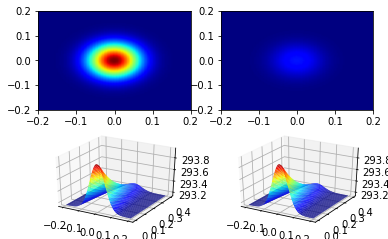

In [6]:
importlib.reload(varoptic.visualize)
myview3d = varoptic.visualize.Visualize3D(xx, yy, zz, clock, hdf5filename='hdf5db/storage.hdf5', hdf5grp='nb4')
myview3d.steadystate_profiles(savepath='images/nb4_steady_state.png')
myview3d.transient_profiles(savepath='videos/nb4_transient.mp4')

In [11]:
import numpy as np

k = (np.abs(zz[0,0,:]-0.1).argmin())
print(k)
print(zz[0,0,k])

12
0.0979591836735


<img width="640" height="480" src="images/nb2_steady_state.png"/>
<video width="640" height="480" controls autoplay loop src="videos/nb2_transient.mp4"/>